In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import missingno as msno
import random
from sklearn.preprocessing import StandardScaler

In [111]:
file_path = '../data/cleaned_data.csv'
data = pd.read_csv(file_path, sep=',')
target = 'Rc (MPa)'
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID                                 148 non-null    str    
 1   Dias curado                        148 non-null    float64
 2   Dosage 1 (Kg/m3)                   148 non-null    float64
 3   Dosage 2 (Kg/m3)                   148 non-null    float64
 4   % Celulosa 1                       148 non-null    float64
 5   % Celulosa 2                       148 non-null    float64
 6   Rf (MPa)                           148 non-null    float64
 7   Rc (MPa)                           148 non-null    float64
 8   Etalement t=0 (mm)                 148 non-null    float64
 9   Teneur en air (%)                  148 non-null    float64
 10  Masse volumique (Kg/m3)            148 non-null    float64
 11  Retrait                            148 non-null    float64
 12  Coef.

<h1>3. Analyse statistique (EDA)</h1>

Text(0.5, 1.0, 'Distribution of Rc (MPa)')

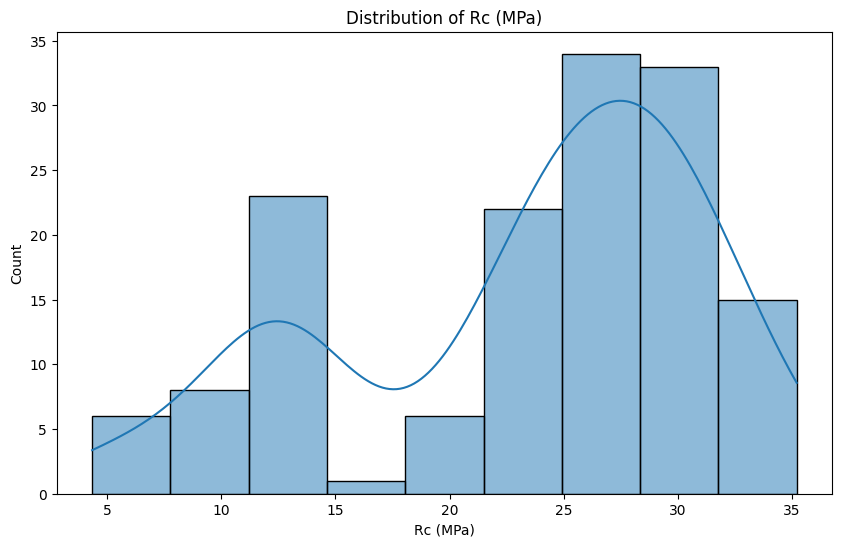

In [112]:
#Distribution of the target variable
plt.figure(figsize=(10, 6))
sns.histplot(data[target], kde=True)
plt.title('Distribution of Rc (MPa)')

C:\Users\matte\AppData\Local\Temp\ipykernel_7992\3242116019.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=['object'])


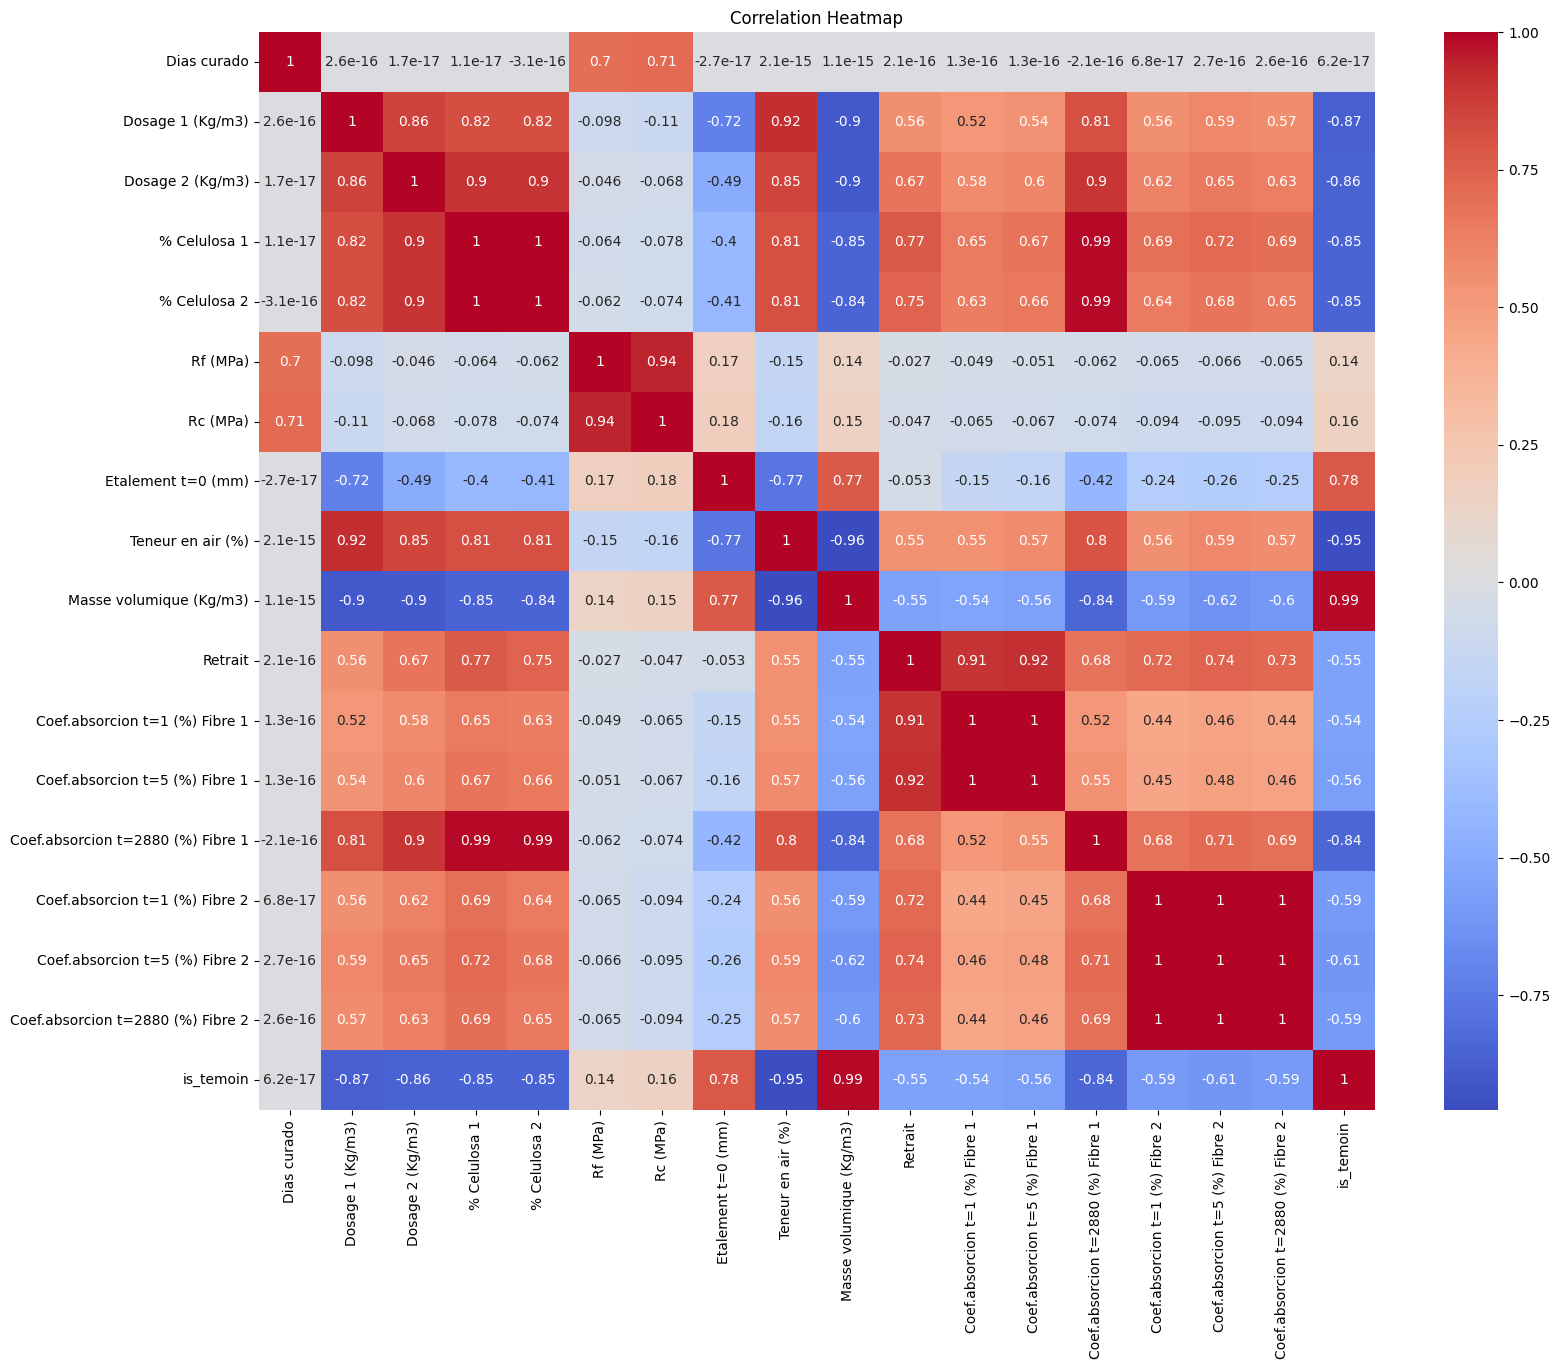

In [113]:
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = data.select_dtypes(include=['object'])

# Correlation heatmap for numerical features
plt.figure(figsize=(18, 14))
sns.heatmap(data[numerical_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

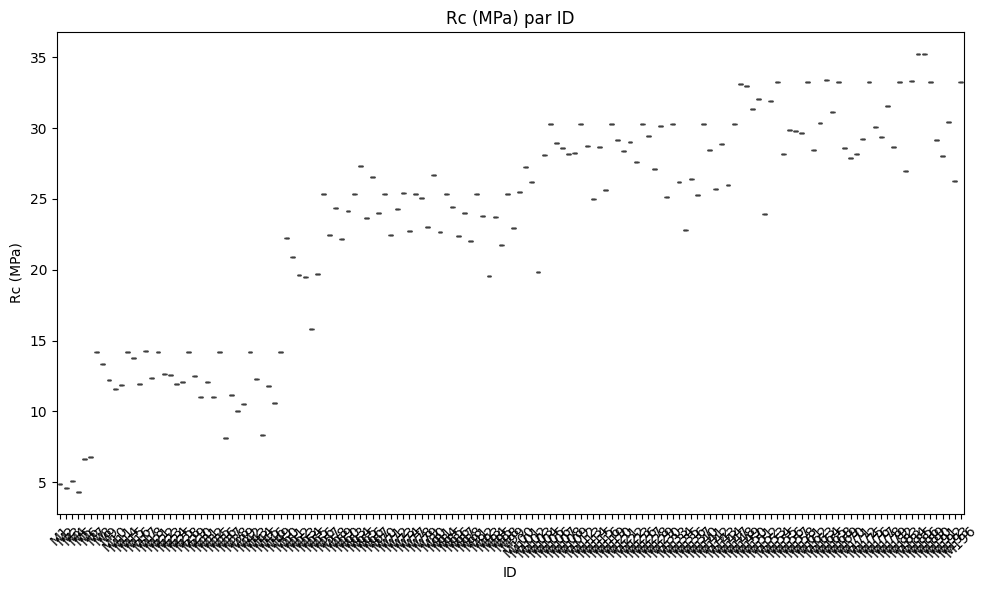

In [114]:
for column in categorical_columns:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=data[column], y=data['Rc (MPa)'])
    plt.title(f'Rc (MPa) par {column}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<h2>3.2 Distribution de la variable cible selon les variables numériques discrètes</h2>

Dias curado a 4 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

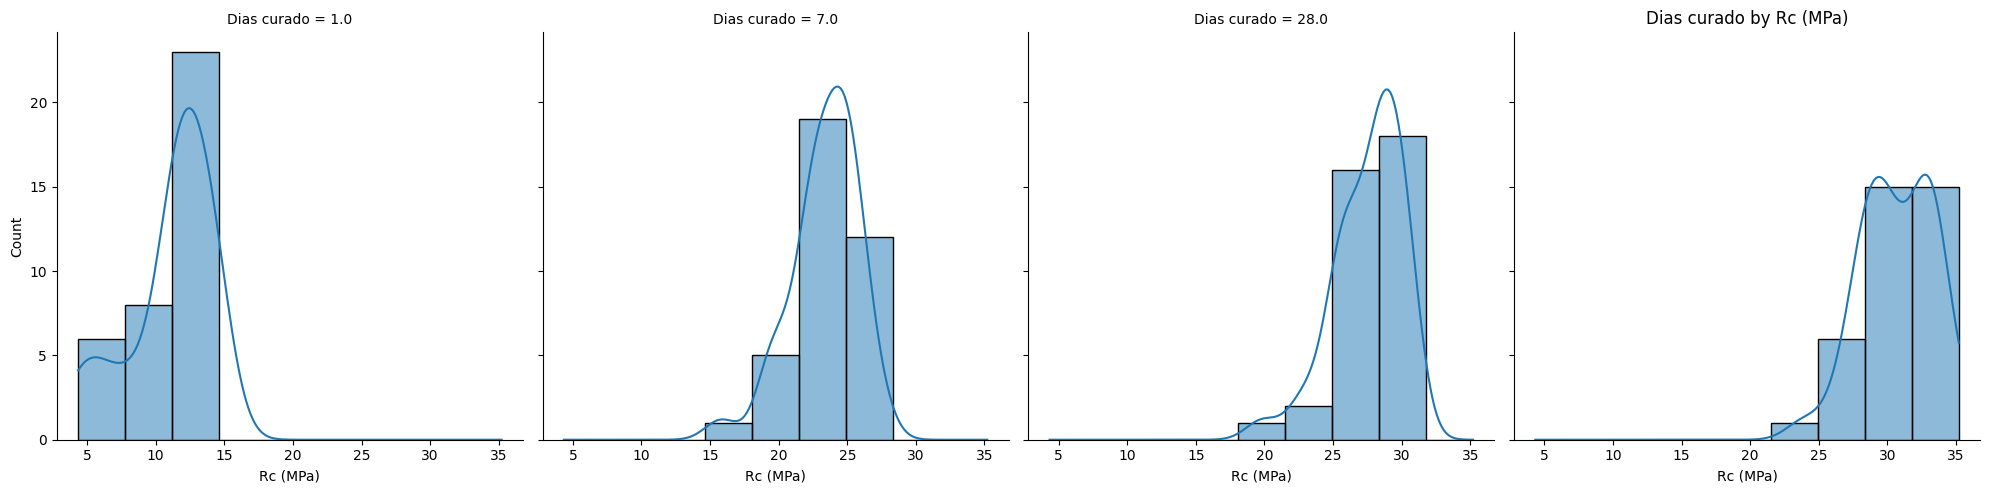

Dosage 1 (Kg/m3) a 5 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

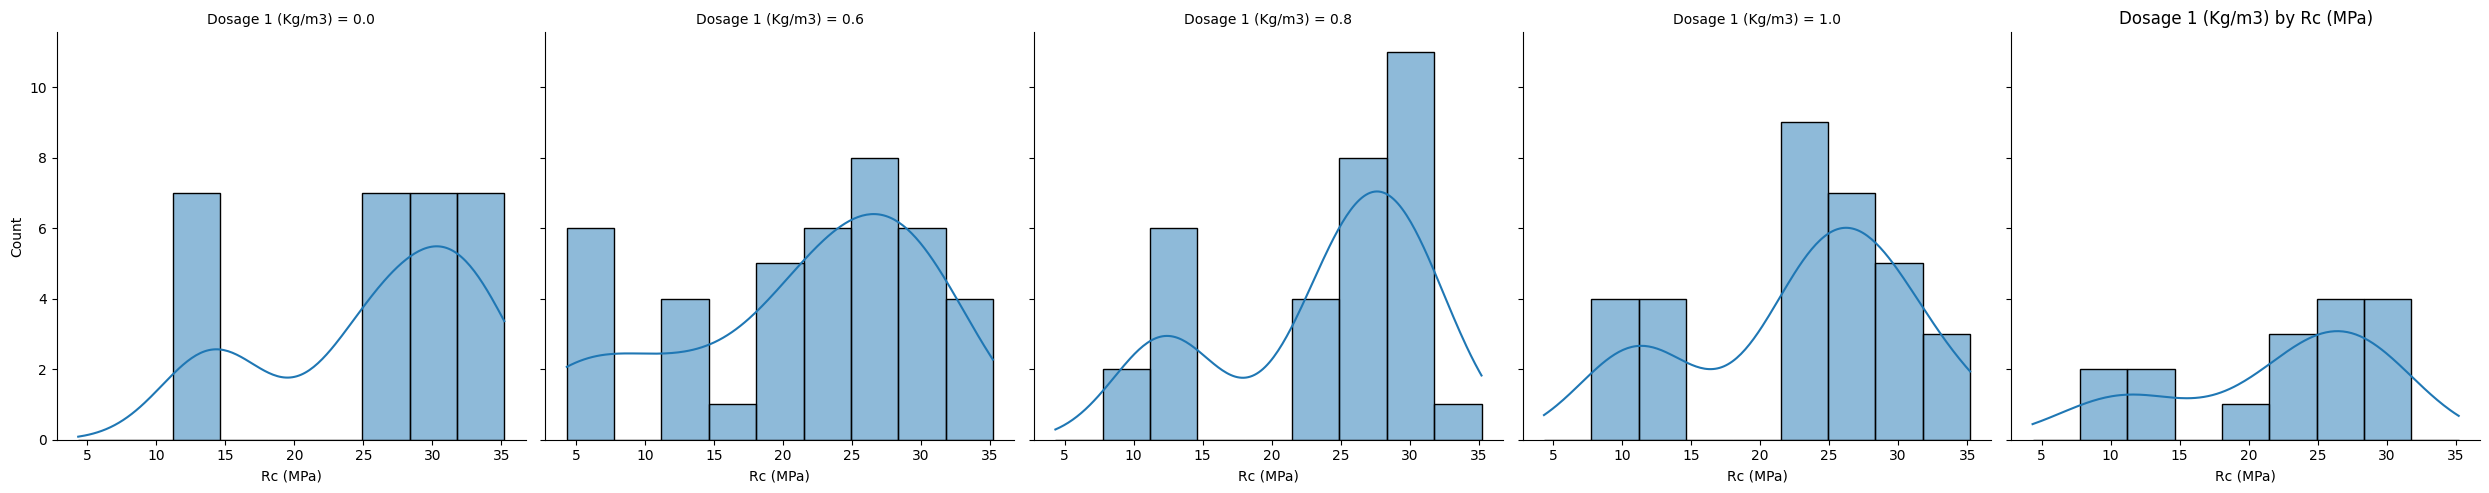

Dosage 2 (Kg/m3) a 8 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

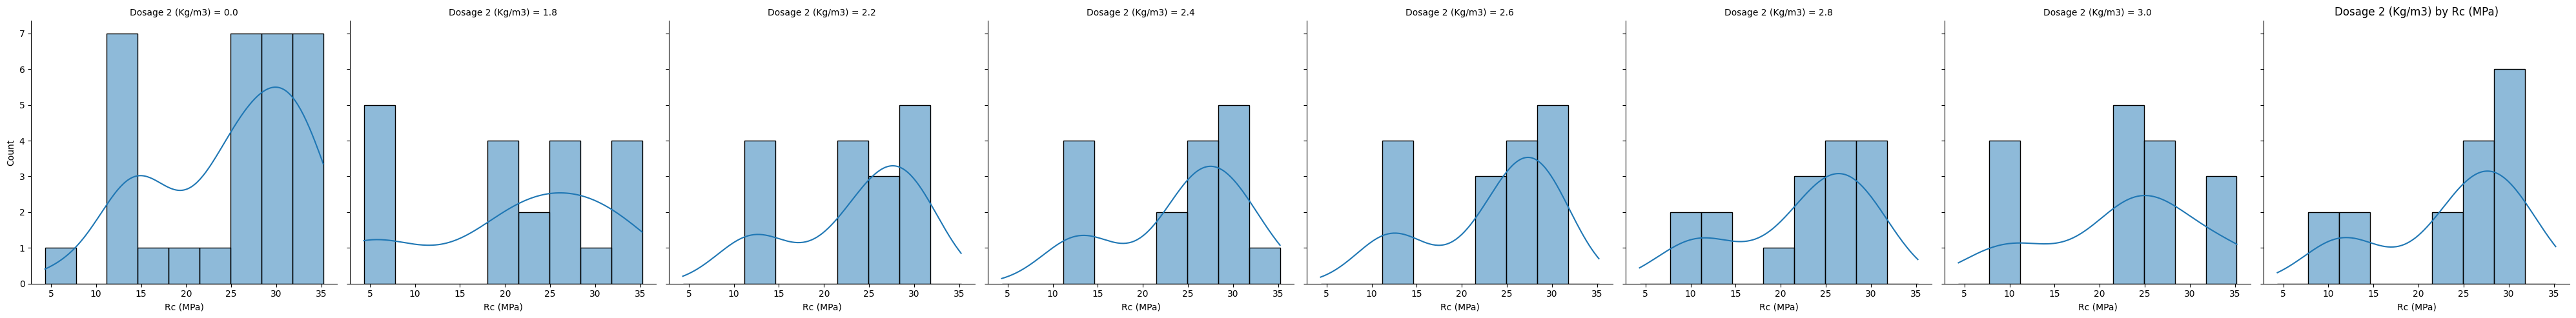

% Celulosa 1 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

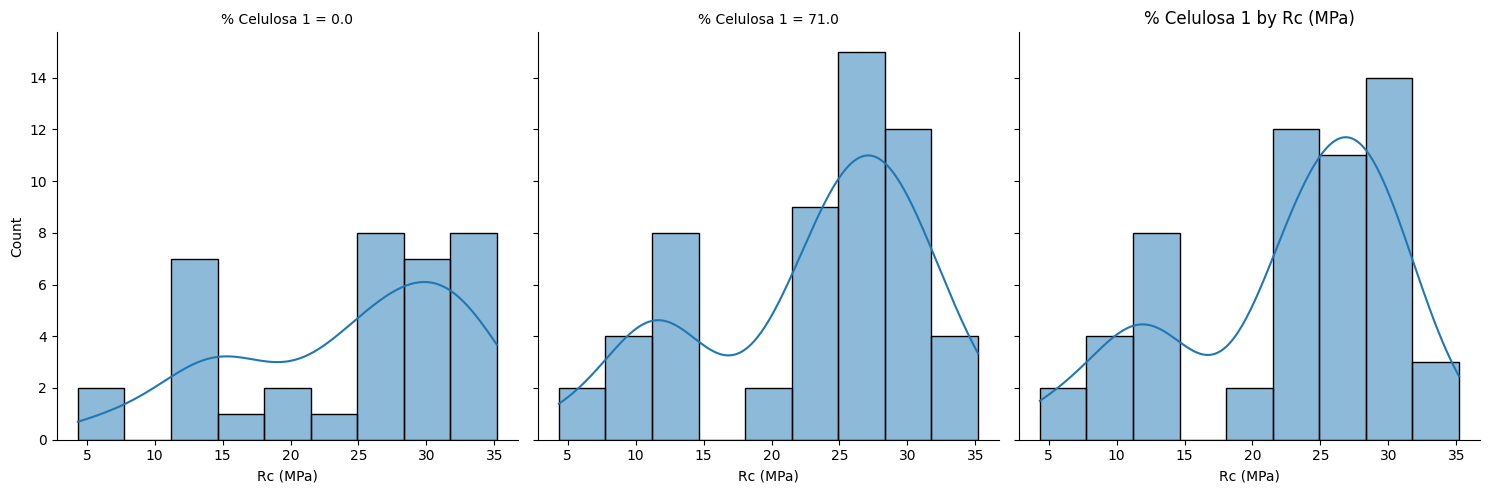

% Celulosa 2 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

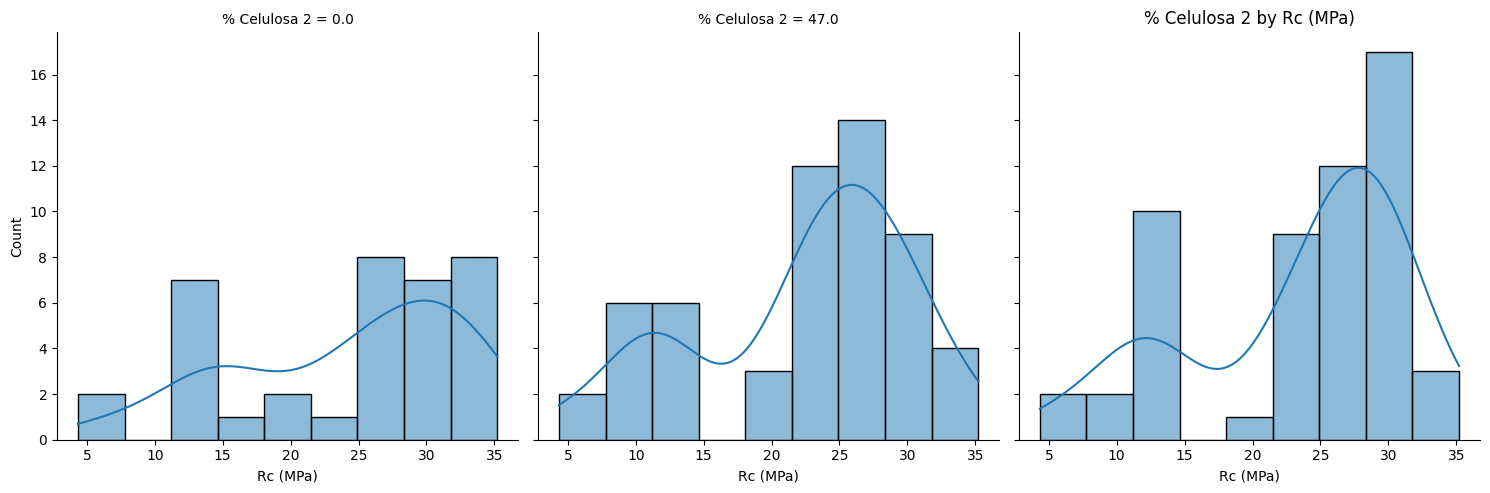

Teneur en air (%) a 11 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

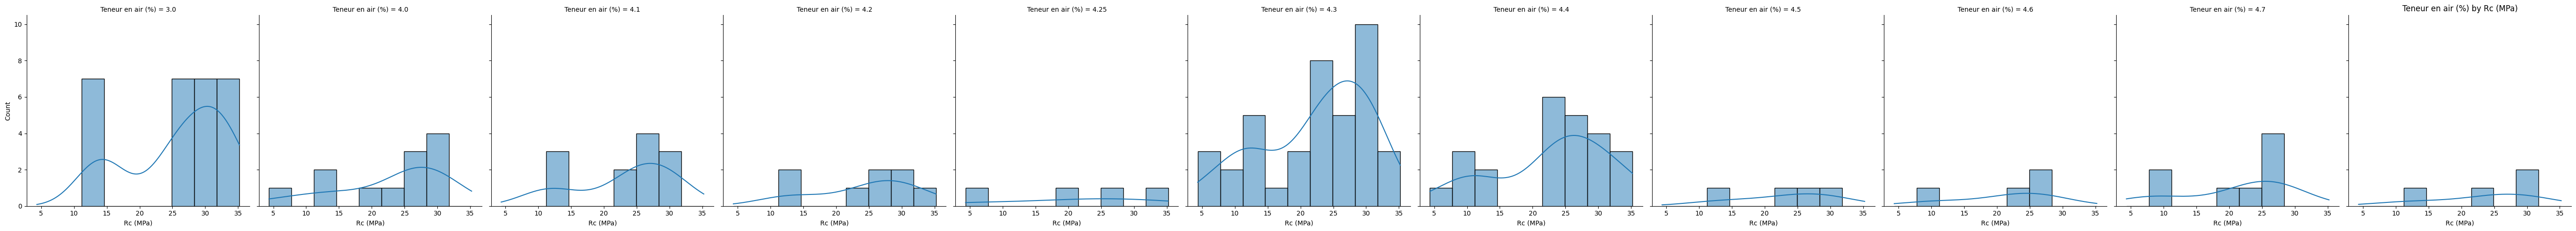

Retrait a 7 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

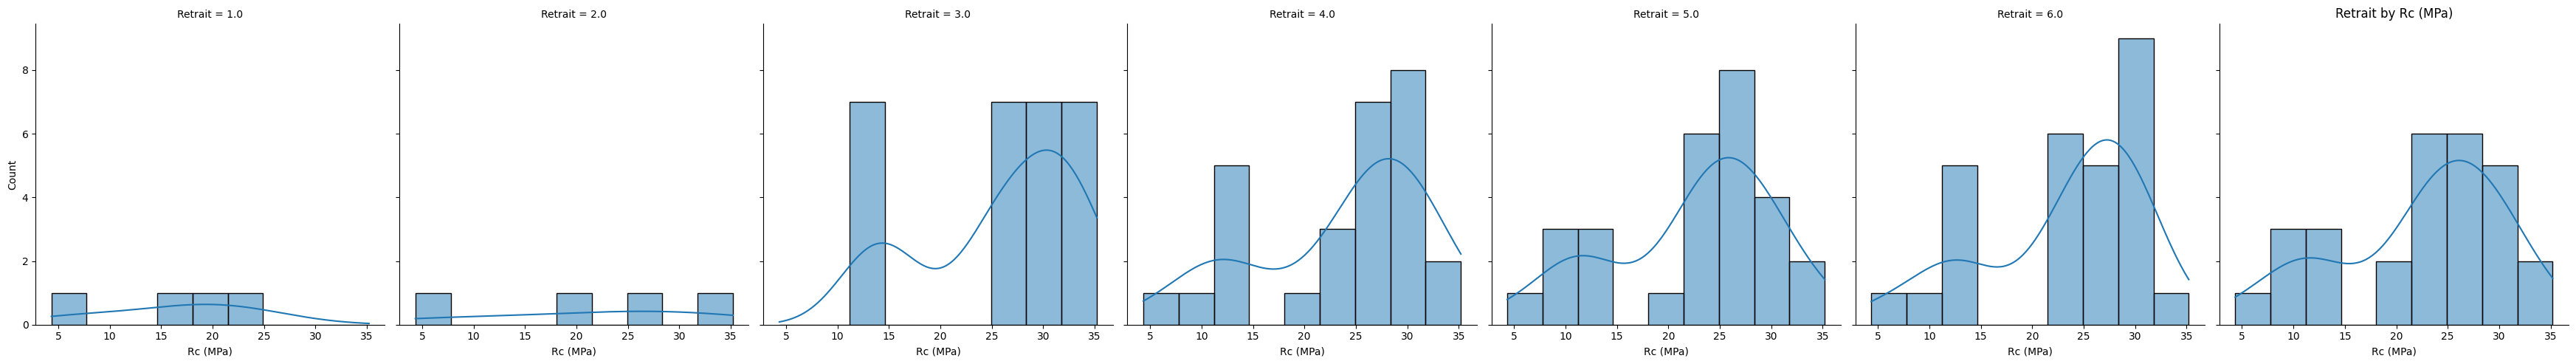

Coef.absorcion t=1 (%) Fibre 1 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

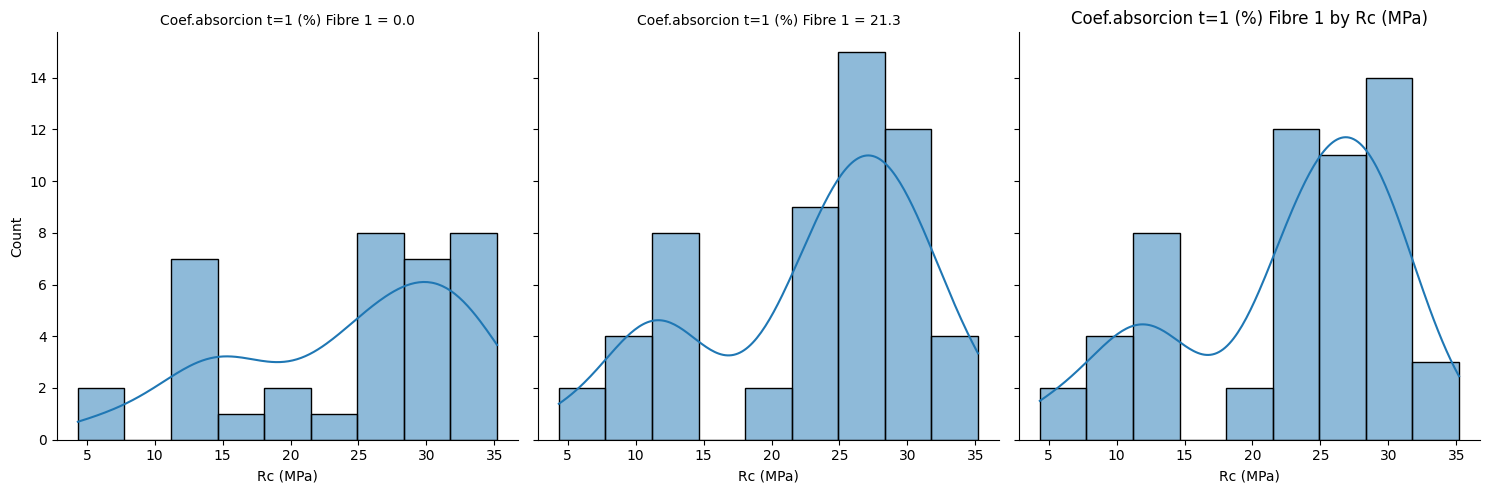

Coef.absorcion t=5 (%) Fibre 1 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

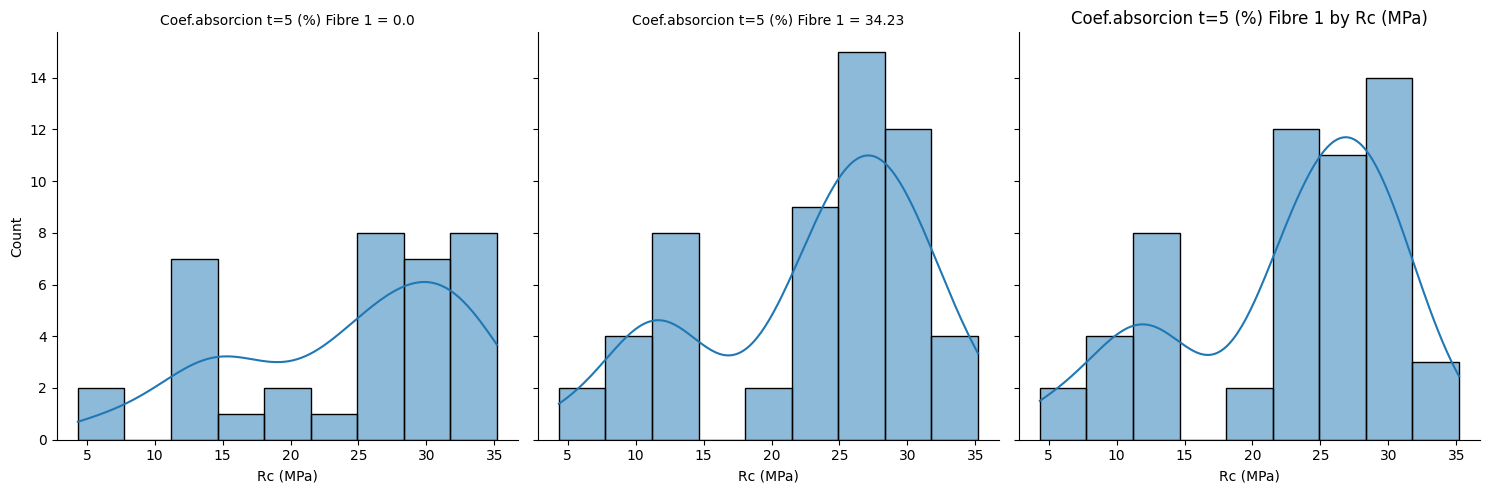

Coef.absorcion t=2880 (%) Fibre 1 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

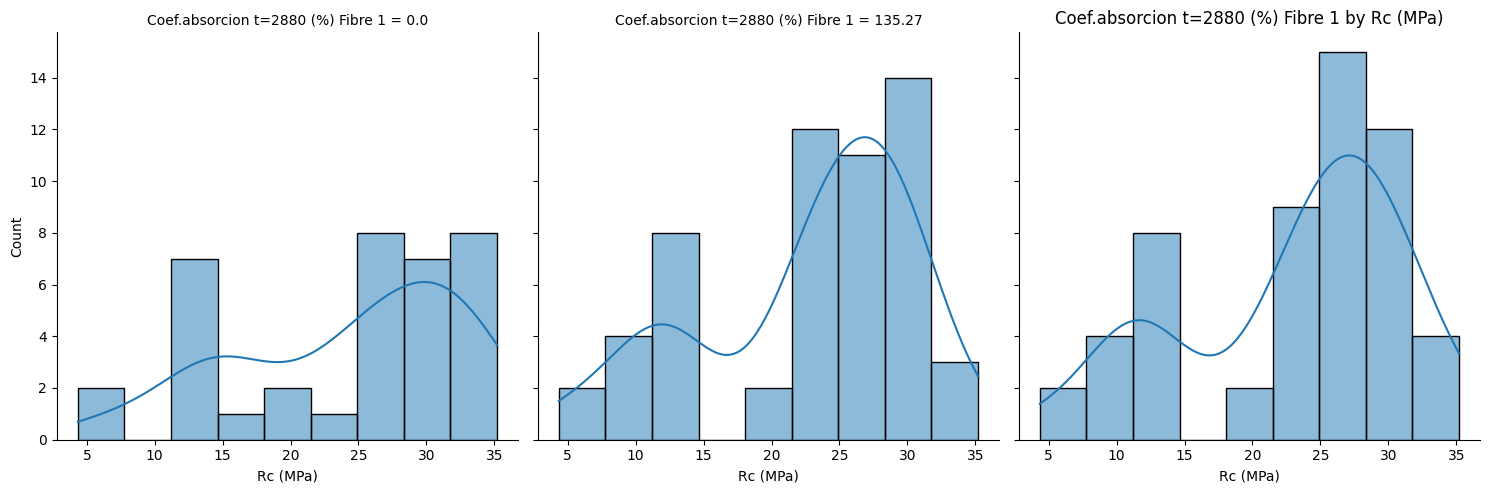

Coef.absorcion t=1 (%) Fibre 2 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

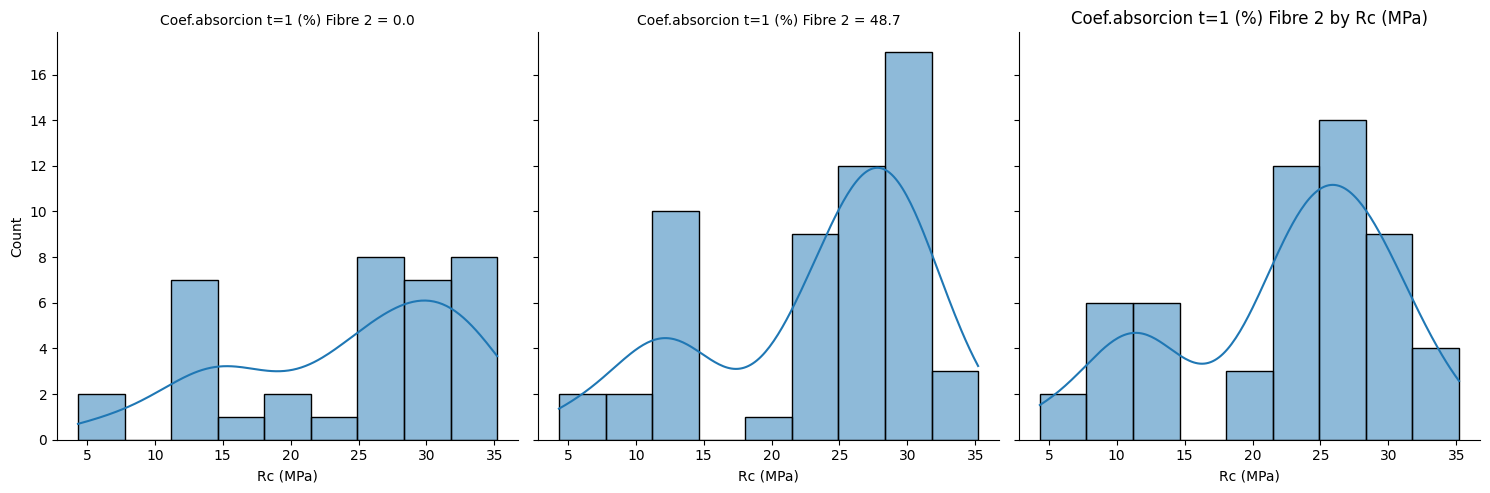

Coef.absorcion t=5 (%) Fibre 2 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

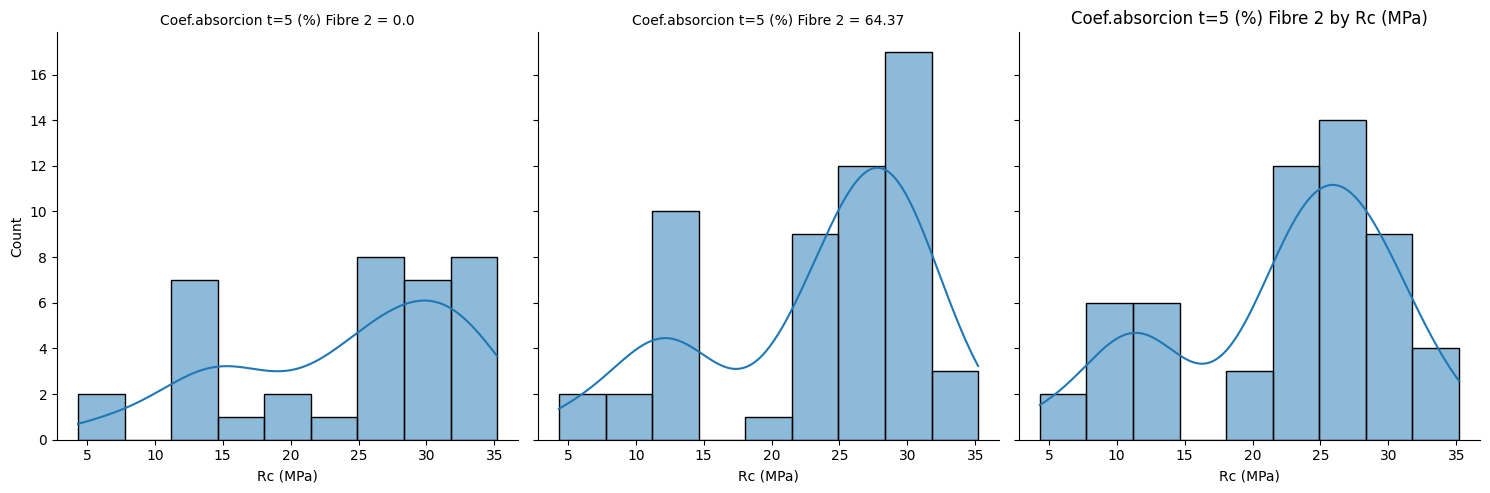

Coef.absorcion t=2880 (%) Fibre 2 a 3 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

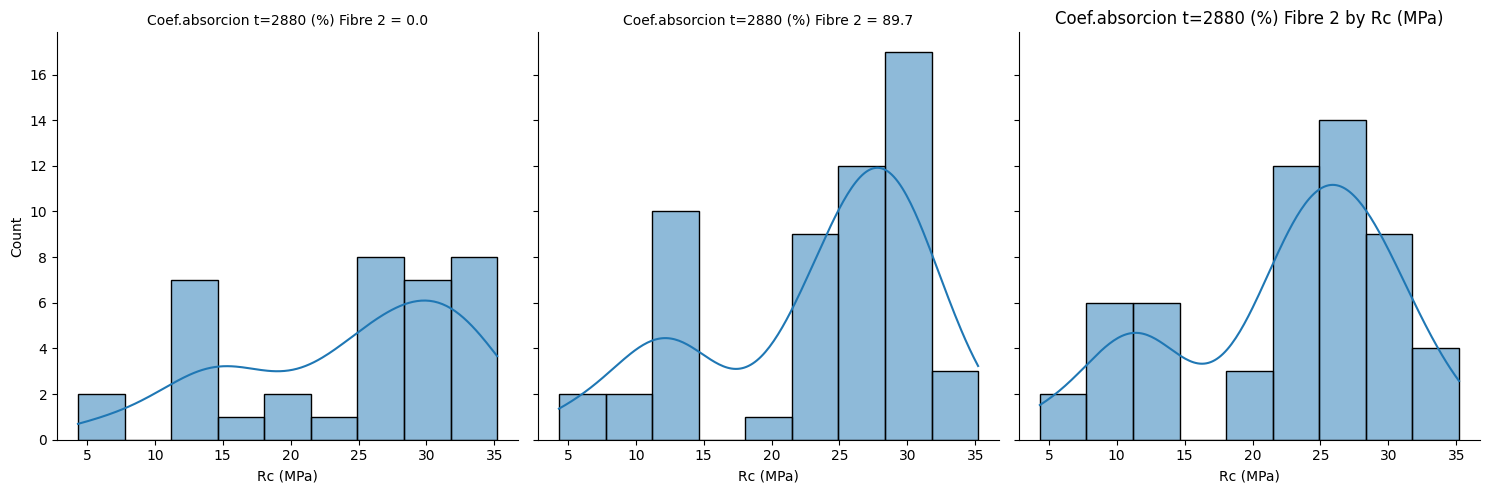

is_temoin a 2 valeurs distinctes, distribution par Rc (MPa):


<Figure size 1000x400 with 0 Axes>

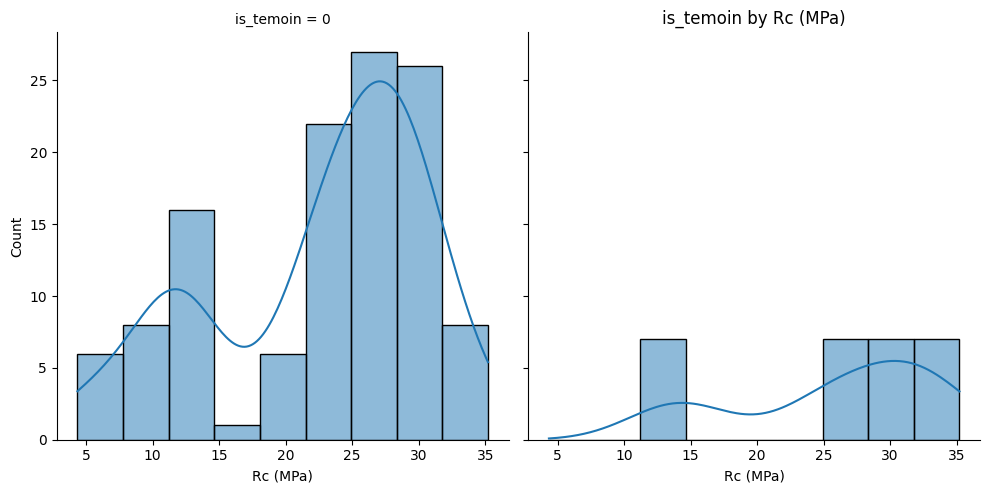

In [115]:
numerical_columns_with_min_distinct_values = [col for col in numerical_columns if data[col].nunique() < 15]
for column in numerical_columns_with_min_distinct_values:
    print(f'{column} a {data[column].nunique()} valeurs distinctes, distribution par {target}:')
    plt.figure(figsize=(10, 4))
    sns.displot(data=data, x=target, col=column, kde=True)
    plt.title(f'{column} by {target}')
    plt.show()

<h2>3.3 Relations linéaires/non-linéaires</h2>

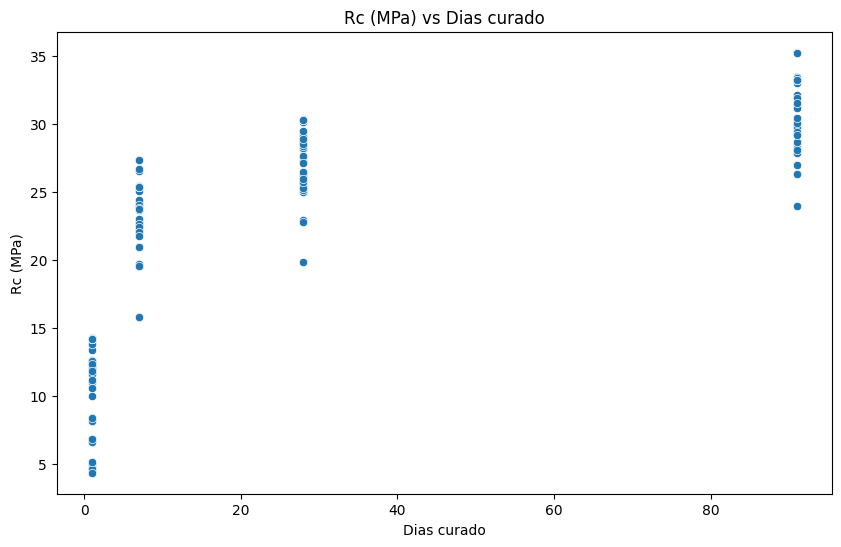

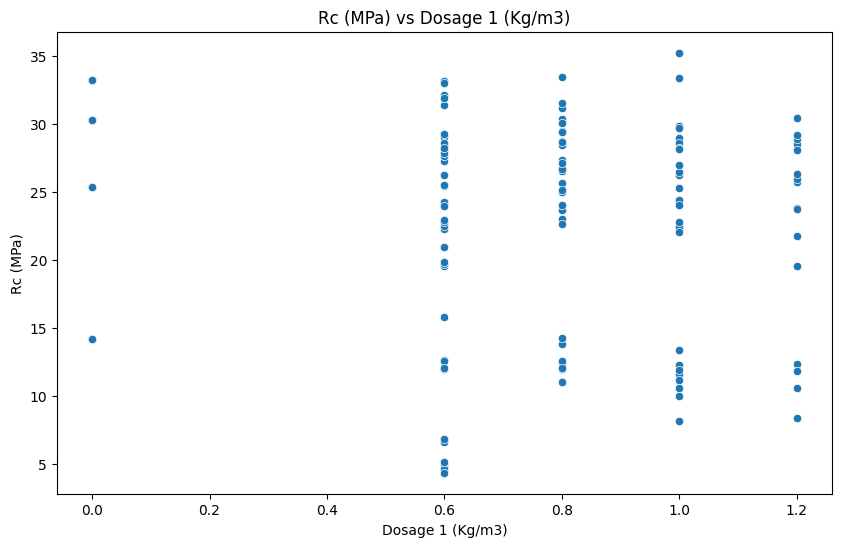

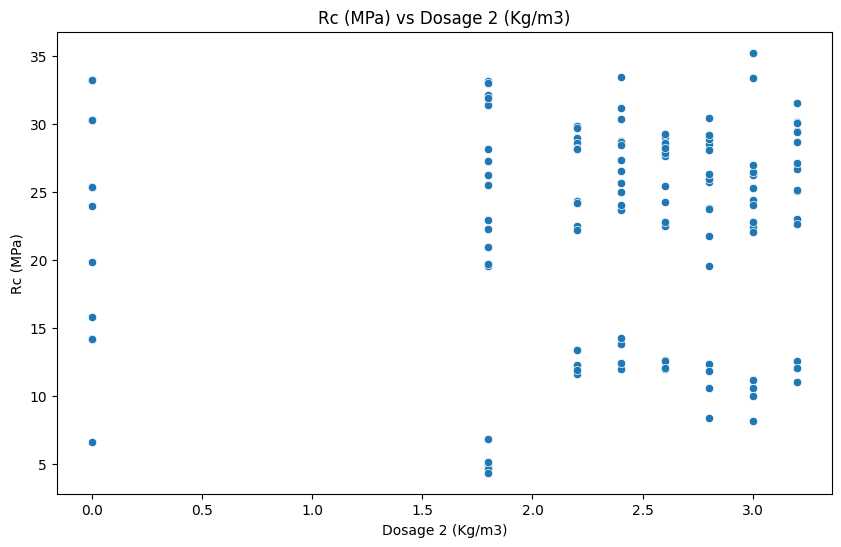

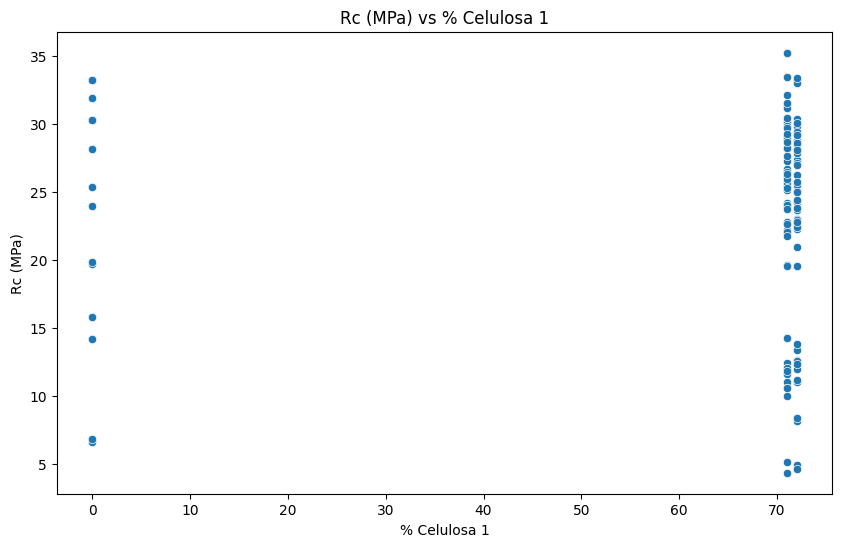

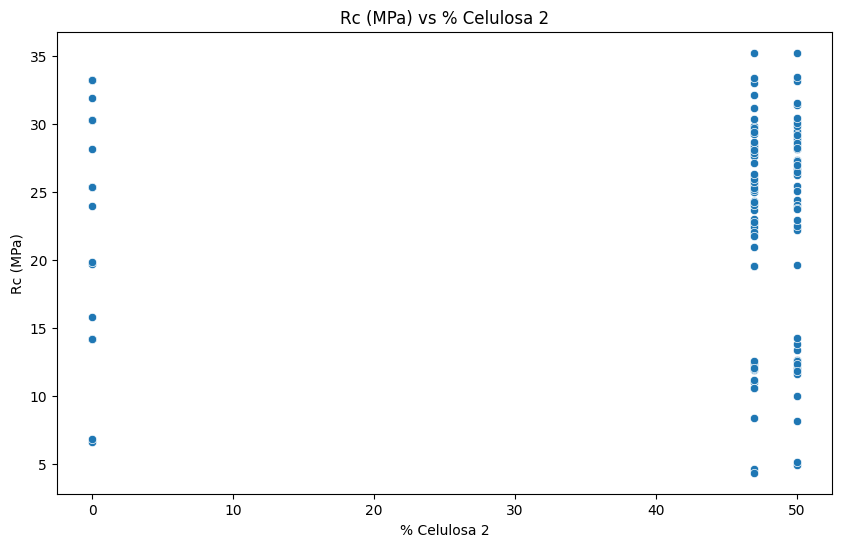

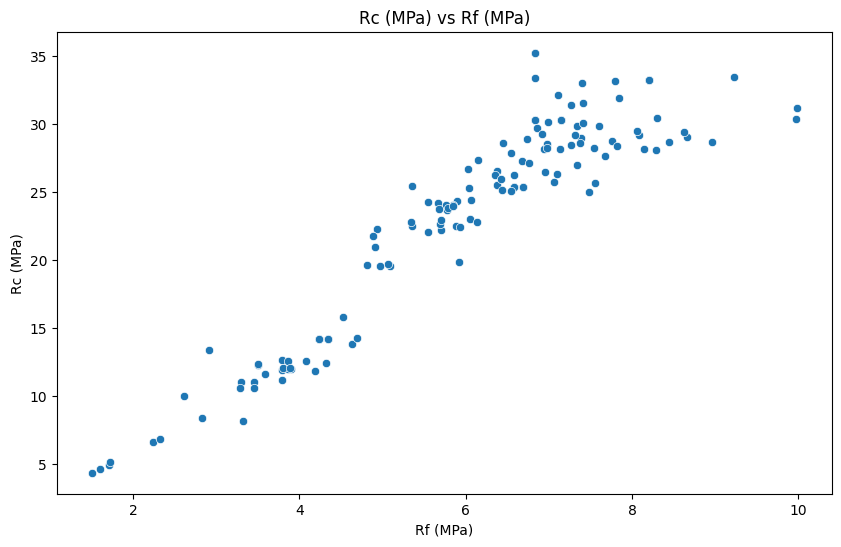

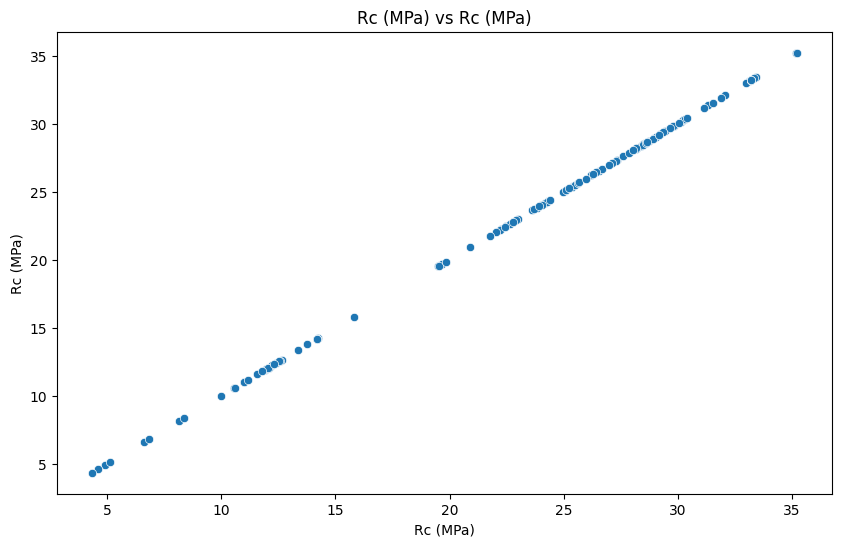

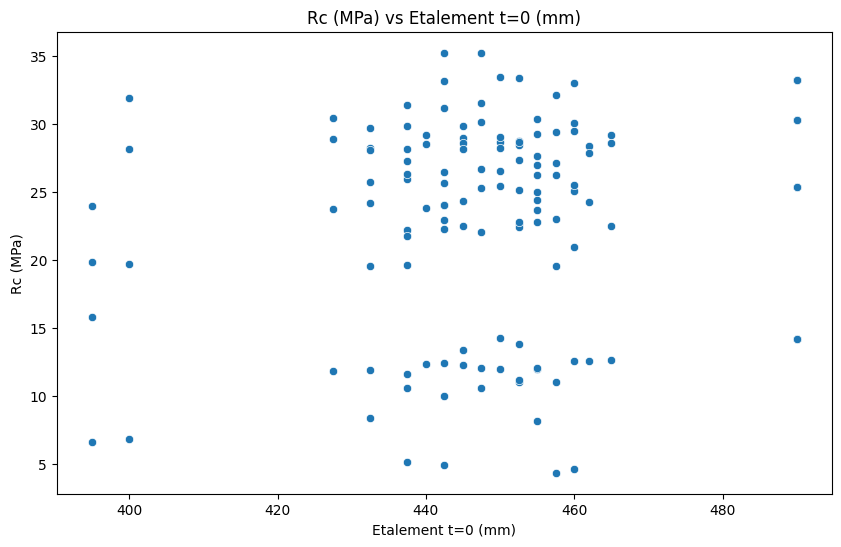

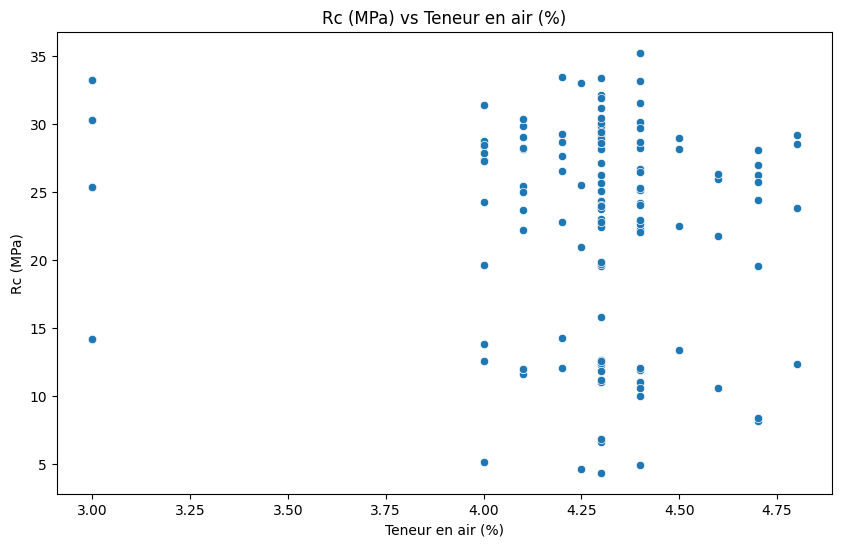

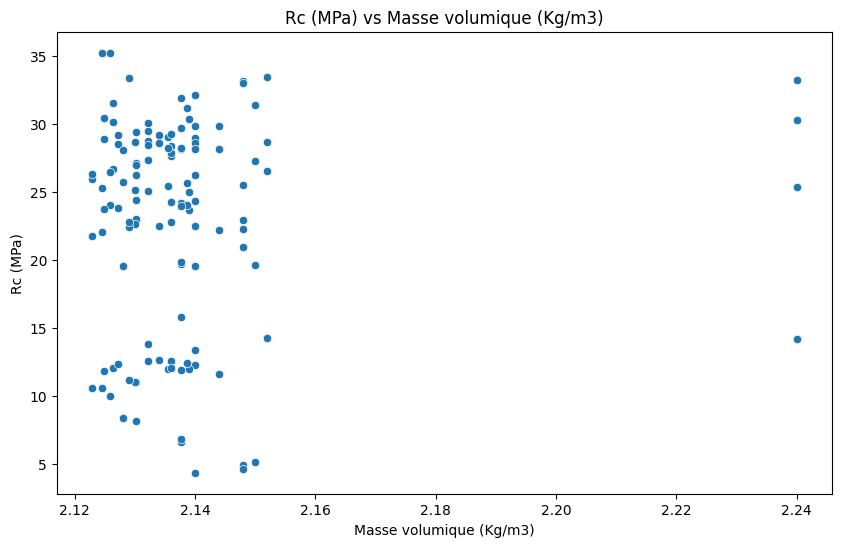

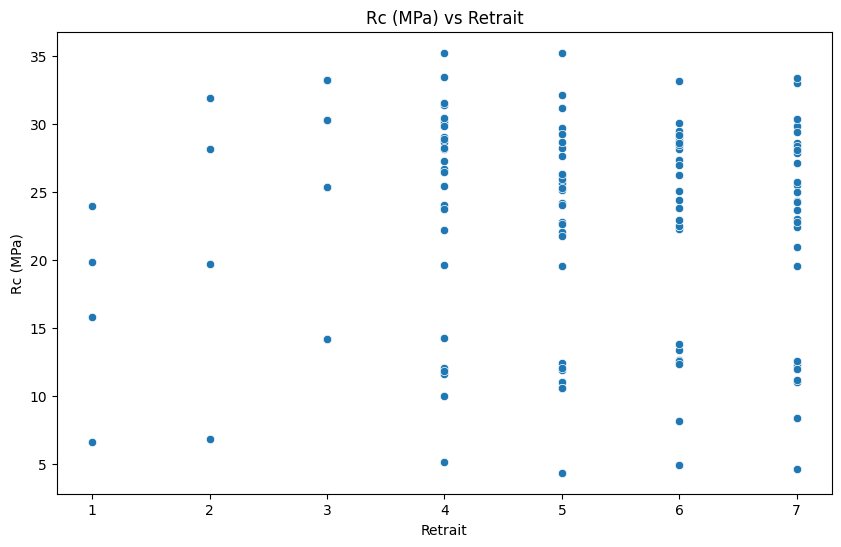

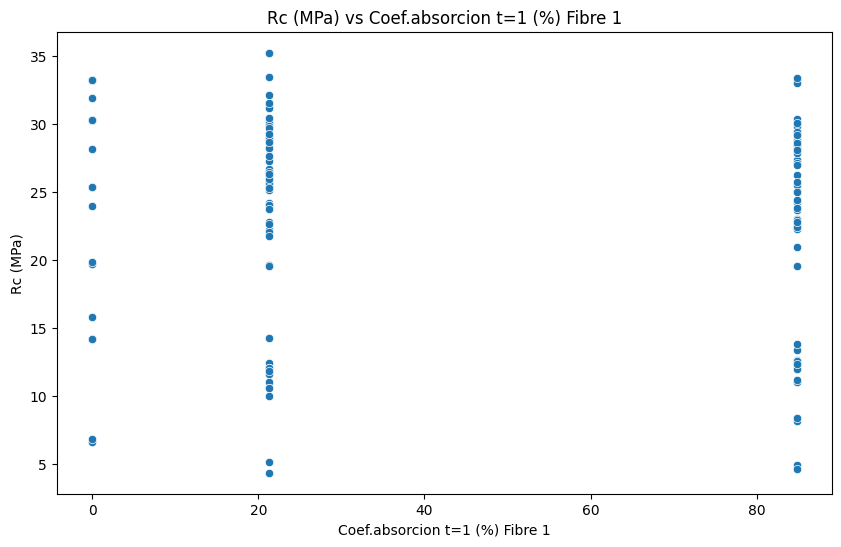

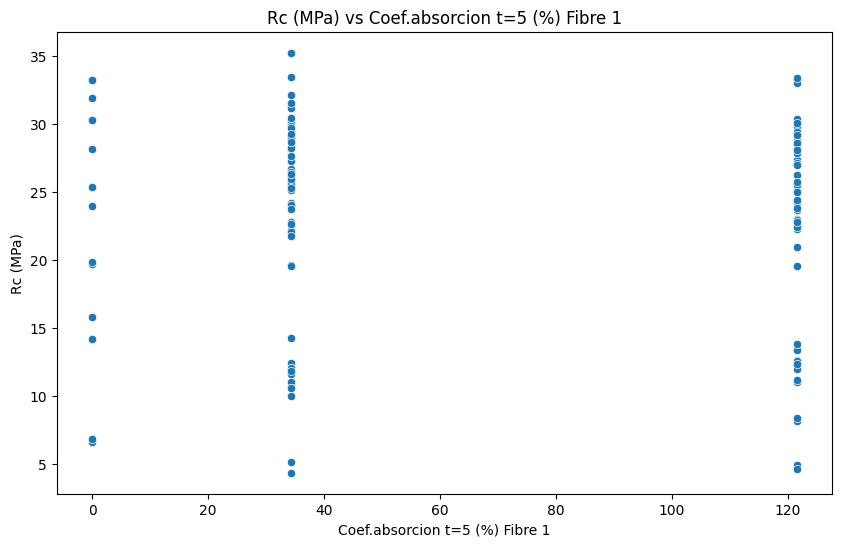

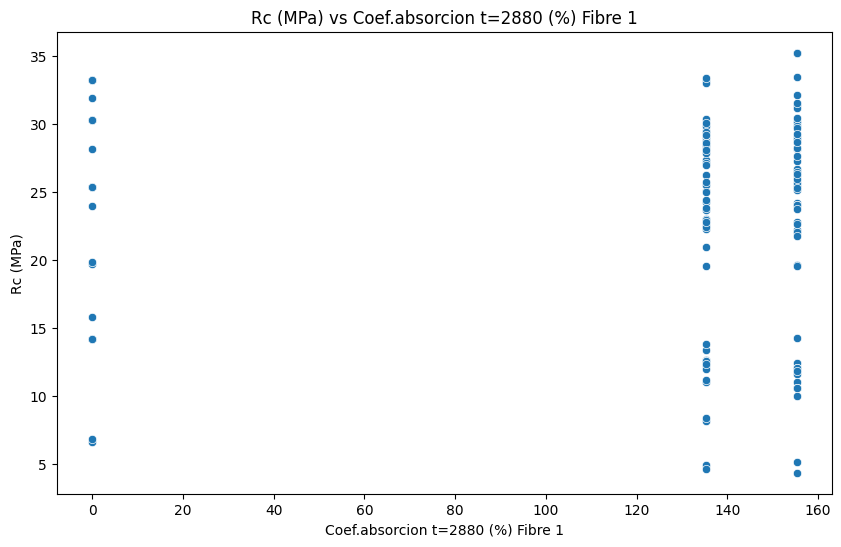

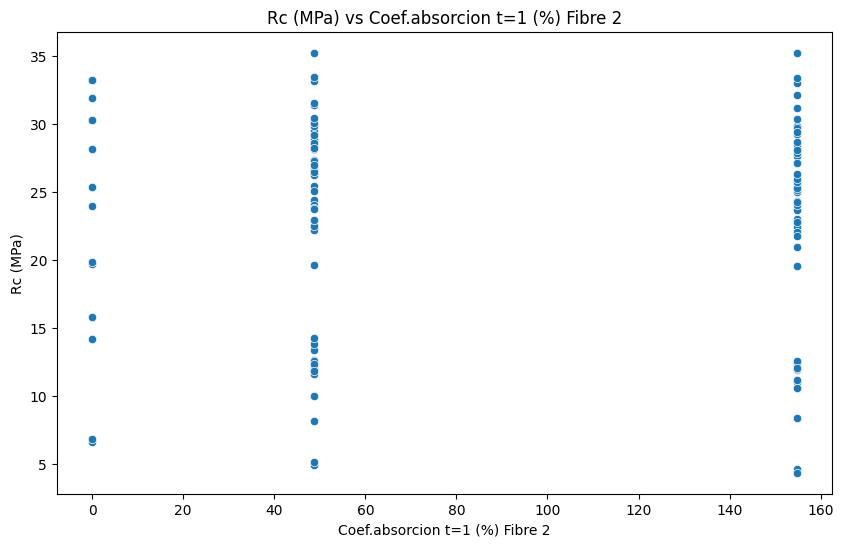

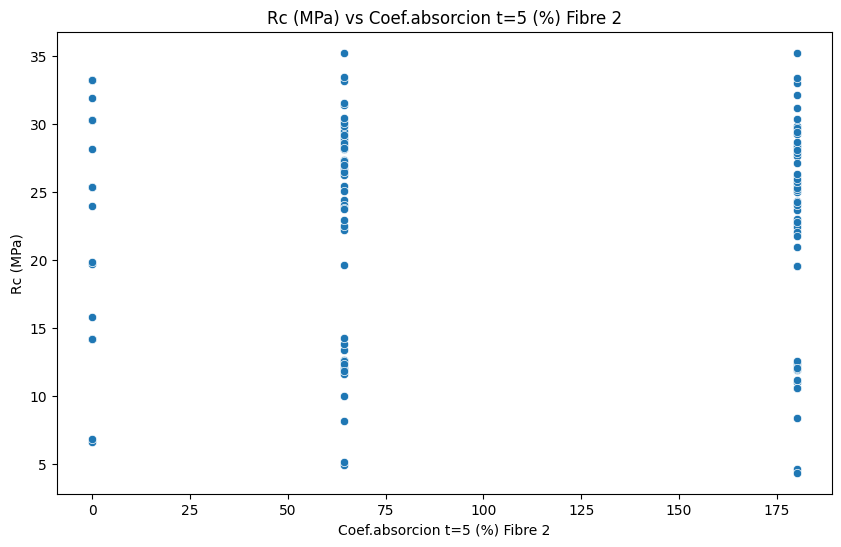

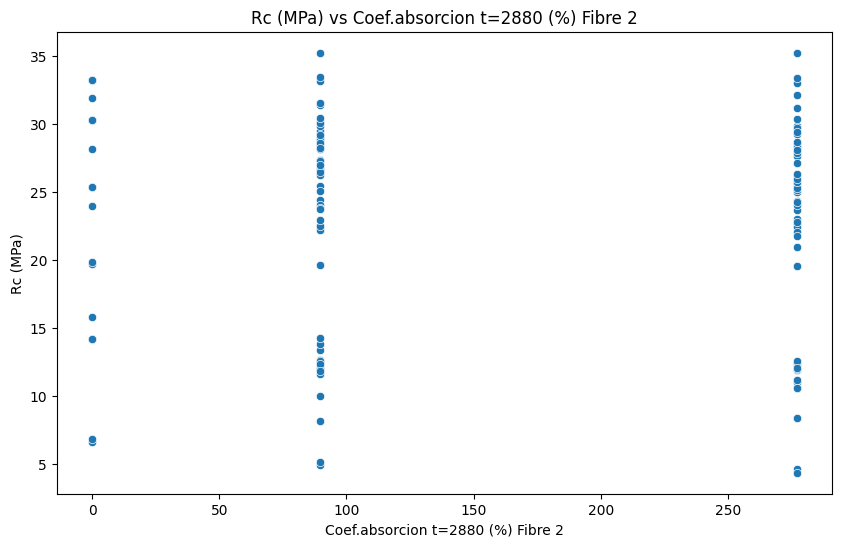

In [116]:
#scatter plots for numerical features vs rc (MPa) scatter plots en fr : nuage de points
cols_to_plot = [col for col in numerical_columns if col not in ['is_temoin'] and 'MEB' not in col]
for column in cols_to_plot:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=data[column], y=data[target])
    plt.title(f'{target} vs {column}')
    plt.xlabel(column)
    plt.ylabel(target)
    plt.show()

<p>Après analyse de la heatmap de corrélation, des scatter plots (pour évaluer la linéarité/non-linéarité des relations) et de la distribution de la variable cible par rapport aux autres variables, Dias curado ressort comme la variable la plus corrélée à Rc (MPa) avec un coefficient de 0.71. Les autres variables numériques présentent des corrélations plus faibles, mais un modèle non linéaire pourra potentiellement en extraire des informations pertinentes, notamment grâce aux patterns de distribution visibles entre ces variables et Rc (MPa).</p>

<h2>3.4 Comptage des modalités catégorielles</h2>

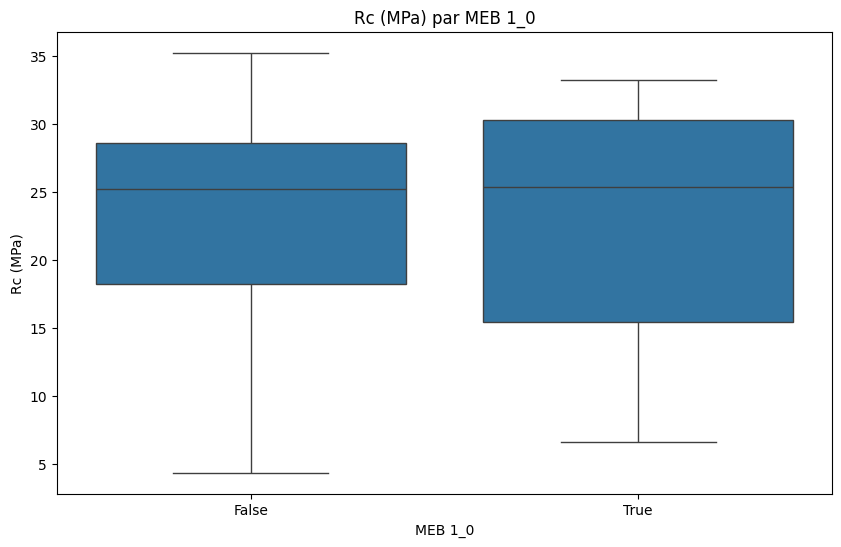

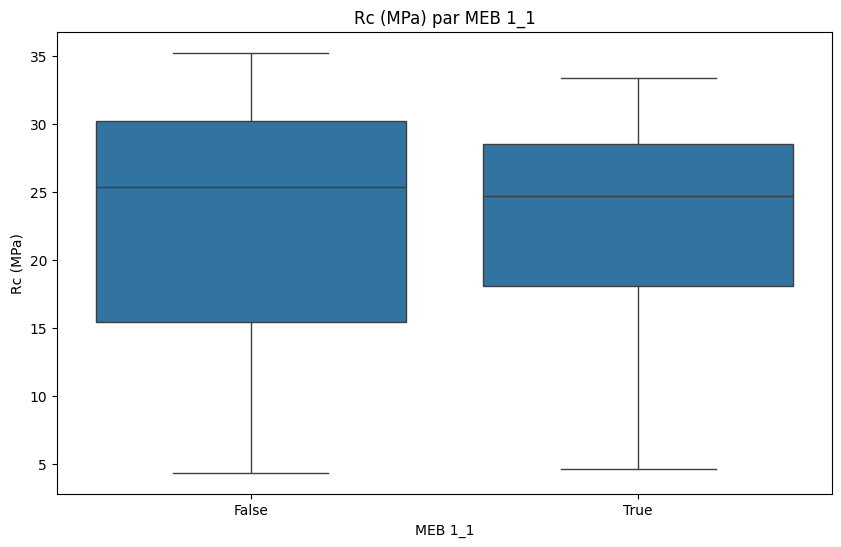

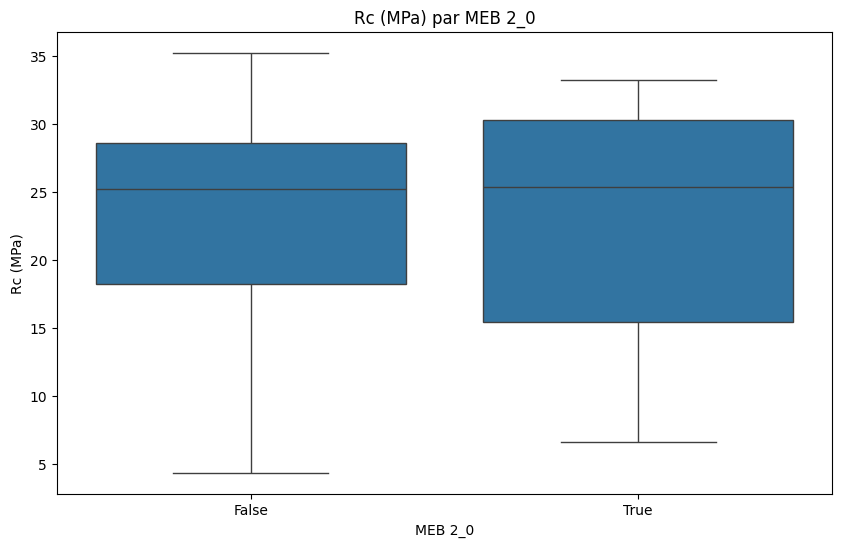

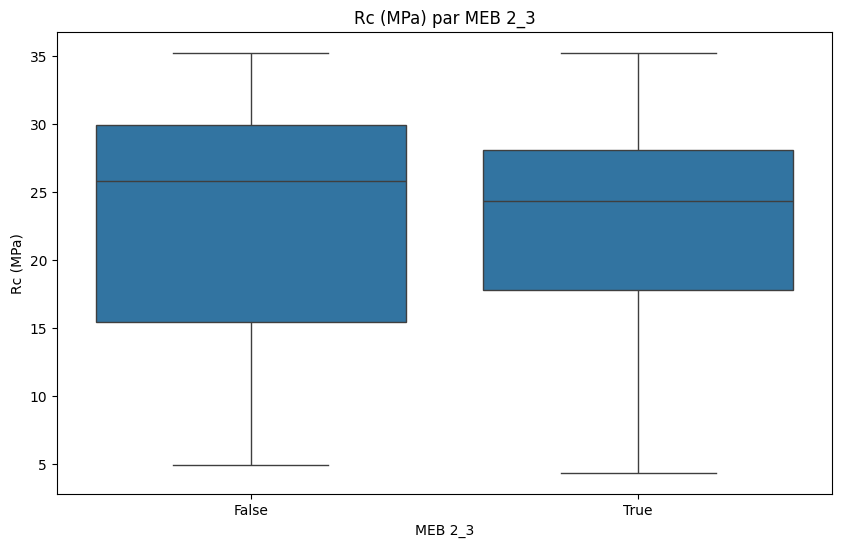

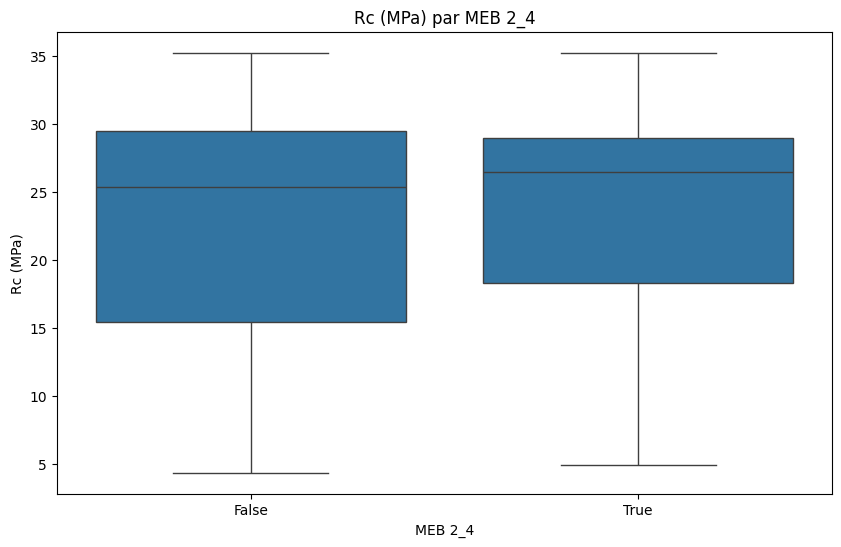

In [117]:
for column in ['MEB 1_0', 'MEB 1_1', 'MEB 2_0', 'MEB 2_3', 'MEB 2_4']:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=data[column], y=data[target])
    plt.title(f'{target} par {column}')
    plt.show()

<h2>4. Standardisation</h2>

In [118]:
data.head()


,ID,Dias curado,Dosage 1 (Kg/m3),Dosage 2 (Kg/m3),% Celulosa 1,% Celulosa 2,Rf (MPa),Rc (MPa),Etalement t=0 (mm),Teneur en air (%),...,Coef.absorcion t=1 (%) Fibre 2,Coef.absorcion t=5 (%) Fibre 2,Coef.absorcion t=2880 (%) Fibre 2,is_temoin,MEB 1_0,MEB 1_1,MEB 1_2,MEB 2_0,MEB 2_3,MEB 2_4
0,M1,1.0,0.6,1.8,72.0,50.0,1.71,4.90,442.5,4.40,...,48.70,64.37,89.70,0,False,True,False,False,False,True
1,M2,1.0,0.6,1.8,72.0,47.0,1.61,4.58,460.0,4.25,...,154.73,180.07,277.07,0,False,True,False,False,True,False
2,M3,1.0,0.6,1.8,71.0,50.0,1.73,5.12,437.5,4.00,...,48.70,64.37,89.70,0,False,False,True,False,False,True
3,M4,1.0,0.6,1.8,71.0,47.0,1.51,4.34,457.5,4.30,...,154.73,180.07,277.07,0,False,False,True,False,True,False
4,M5,1.0,0.6,0.0,0.0,0.0,2.24,6.62,395.0,4.30,...,0.00,0.00,0.00,0,True,False,False,True,False,False


In [119]:
scaler = StandardScaler()
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
data[numerical_columns] = scaler.fit_transform(data[numerical_columns])
data.head()

,ID,Dias curado,Dosage 1 (Kg/m3),Dosage 2 (Kg/m3),% Celulosa 1,% Celulosa 2,Rf (MPa),Rc (MPa),Etalement t=0 (mm),Teneur en air (%),...,Coef.absorcion t=1 (%) Fibre 2,Coef.absorcion t=5 (%) Fibre 2,Coef.absorcion t=2880 (%) Fibre 2,is_temoin,MEB 1_0,MEB 1_1,MEB 1_2,MEB 2_0,MEB 2_3,MEB 2_4
0,M1,-0.862632,-0.213893,-0.173101,0.583187,0.637780,-2.412281,-2.322533,-0.469905,0.600273,...,-0.445301,-0.386917,-0.433242,-0.483046,False,True,False,False,False,True
1,M2,-0.862632,-0.213893,-0.173101,0.583187,0.493891,-2.468374,-2.363173,0.301358,0.326074,...,1.224645,1.205012,1.220795,-0.483046,False,True,False,False,True,False
2,M3,-0.862632,-0.213893,-0.173101,0.550592,0.637780,-2.401062,-2.294592,-0.690266,-0.130924,...,-0.445301,-0.386917,-0.433242,-0.483046,False,False,True,False,False,True
3,M4,-0.862632,-0.213893,-0.173101,0.550592,0.493891,-2.524468,-2.393653,0.191178,0.417474,...,1.224645,1.205012,1.220795,-0.483046,False,False,True,False,True,False
4,M5,-0.862632,-0.213893,-1.774285,-1.763657,-1.760376,-2.114986,-2.104090,-2.563333,0.417474,...,-1.212313,-1.272591,-1.225083,-0.483046,True,False,False,True,False,False


<p></p>

<h2>5 Sélection et cohérence des features</h2>

<p style="color: grey;">
La colonne <strong>Rf (MPa)</strong> est supprimée afin d'éviter tout data leakage. En effet, la résistance à la flexion et la résistance à la compression sont mesurées simultanément lors du même test mécanique, ce qui en fait des variables fortement corrélées (0.9388). Conserver Rf comme feature reviendrait à fournir au modèle une information qu'il ne pourrait pas avoir en conditions réelles, rendant la prédiction de Rc sans intérêt pratique.
</p>

In [120]:
print(data['Rf (MPa)'].corr(data['Rc (MPa)']))
data.drop('Rf (MPa)', axis=1, inplace=True)

0.9388896296639129


<p style="color: grey;">
La colonne <strong>ID</strong> est également supprimée car elle ne représente qu'un identifiant technique sans aucune valeur prédictive pour le modèle.
</p>

In [121]:
data.drop('ID', axis=1, inplace=True)

<h2>Export CSV</h2>

In [ ]:
# export en csv 
data.to_csv('../data/cleaned_data.csv', index=False)